# Where to shoot next

This notebook explains the problem and walks you through the starting policy,
`my_policy.py`, one piece at a time. It takes about 15 minutes. The brief is in `README.md`.

**How we judge.** We value a daring or thoughtful idea just as much as a strong score. After
you submit, we will schedule a chat with Luca, our CSO, where you explain what you did and
why.

**On Colab:**

1. Run the first cell. It connects your Google Drive and finds the `cryoem-challenge`
   folder there, or copies it from GitHub the first time. It then downloads the data.
2. Your work is saved in that folder. Next time, open `cryoem-challenge/START_HERE.ipynb`
   from your Drive with Google Colaboratory (install it in your Drive apps if needed).

**Locally:** open this notebook from the `cryoem-challenge` folder.

In [ ]:
import os, subprocess, sys, zipfile
from pathlib import Path

REPO = "https://github.com/Tetherline-Dev/cryoem-challenge"

def find_challenge(drive):
    """The cryoem-challenge folder in your Drive (up to two levels deep), else a
    cryoem-challenge.zip there, unpacked next to it, else a fresh copy from GitHub."""
    for pattern in ("cryoem-challenge", "*/cryoem-challenge", "*/*/cryoem-challenge"):
        for folder in sorted(drive.glob(pattern)):
            if (folder / "main.py").exists():
                return folder
    for pattern in ("cryoem-challenge.zip", "*/cryoem-challenge.zip"):
        for z in sorted(drive.glob(pattern)):
            with zipfile.ZipFile(z) as f:
                f.extractall(z.parent)
            return z.parent / "cryoem-challenge"
    subprocess.run(["git", "clone", "--depth", "1", REPO, str(drive / "cryoem-challenge")], check=True)
    return drive / "cryoem-challenge"

if "google.colab" in sys.modules:
    from google.colab import drive
    drive.mount("/content/drive")
    os.chdir(find_challenge(Path("/content/drive/MyDrive")))
sys.path.insert(0, str(Path.cwd()))

from challenge.data import download_data
download_data()      # the first time only: the four sessions from Hugging Face into data/

# Cells that start with %%policy_part ARE my_policy.py: they run here as usual, and
# save_policy() writes them, in order, back into my_policy.py.
from IPython.core.magic import register_cell_magic
POLICY_PARTS = {}

@register_cell_magic
def policy_part(title, cell):
    POLICY_PARTS[title.strip()] = cell.strip("\n")
    get_ipython().run_cell(cell)

def save_policy(path="my_policy.py"):
    header = Path(path).read_text().partition("\n# %% ")[0].rstrip("\n")
    body = "\n\n\n".join(f"# %% {t}\n{c}" for t, c in POLICY_PARTS.items())
    Path(path).write_text(header + "\n\n" + body + "\n")
    print(f"wrote {path} ({len(POLICY_PARTS)} parts)")

print("ready in", Path.cwd())

## The problem

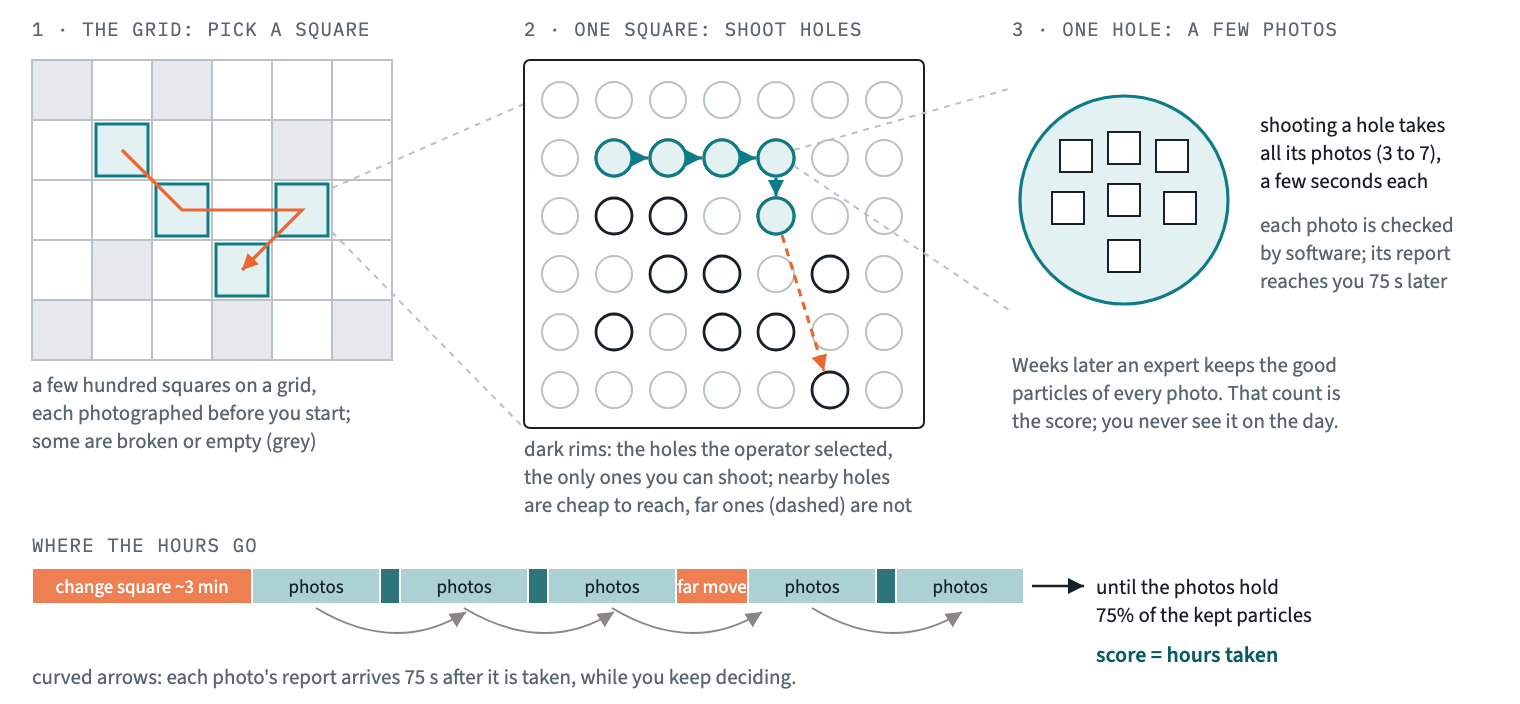

An electron microscope photographs frozen protein molecules to work out their 3-D shape.
They sit in thin ice inside tiny **holes**. The holes are grouped in **squares**, and the
squares sit on a **grid**.

You choose a square, then holes in it. Each hole gives a few photos (micrographs). Software
reports on each photo 75 s after it is taken. Weeks later an expert keeps the good particles,
and that count is the score.

Time goes into photos, moves between holes and moves between squares. Holes close to
where the stage is parked are a quick image shift away; any other hole needs a stage move of
about a minute. The goal is 75% of the expert's particles in the fewest instrument hours.

## What goes in, what comes out

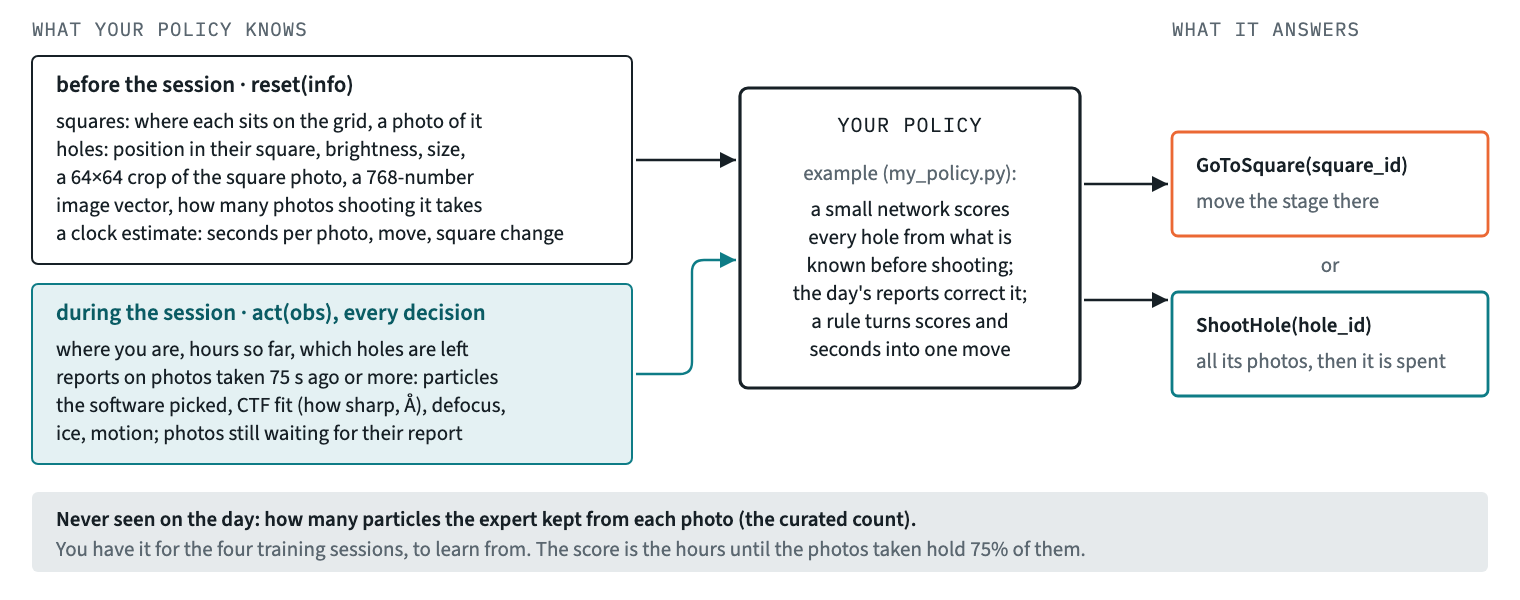

Your policy gets `info` once per session, then an `obs` at every decision. It answers
`GoToSquare(square_id)` or `ShootHole(hole_id)`. That is the whole interface.

## 1. A quick look at the data

Four recorded sessions, each with:

* its squares and the holes the operator selected;
* one row per photo, with the software's report and the expert's count;
* the overview images.

`DATA.md` lists every column.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from challenge import training_sessions, LIVE_COLUMNS

sessions = training_sessions()
by_name = {s.name: s for s in sessions}
for s in sessions:
    print(s)
by_name["delta10"].holes.head(3)

One square of delta10. Each dot is a hole the operator selected, coloured by the particles
the expert kept per photo. Good and bad holes sit side by side, and nothing obvious in the
image separates them.

In [ ]:
s = by_name["delta10"]
square = s.holes["square_id"].value_counts().index[0]
img = s.square_image(square)
k = img.shape[1] / s.squares.set_index("square_id").loc[square, "overview_width_px"]
h = s.holes[s.holes["square_id"] == square]
fig, ax = plt.subplots(figsize=(7, 5.5))
ax.imshow(img, cmap="gray"); ax.axis("off")
sc = ax.scatter(h["x_px"] * k, h["y_px"] * k, c=s.hole_yield().reindex(h["hole_id"]), s=16, cmap="viridis")
plt.colorbar(sc, label="particles kept per photo"); plt.show()

y = s.hole_yield().dropna().sort_values()
fig, axes = plt.subplots(2, 8, figsize=(13, 3.6))
for row, ids in zip(axes, (y.index[-8:][::-1], y.index[:8])):
    for ax, hid in zip(row, ids):
        ax.imshow(s.hole_image(hid), cmap="gray", vmin=0, vmax=255); ax.set_title(f"{y[hid]:.0f}", fontsize=9); ax.axis("off")
fig.suptitle("the crops your policy sees: best holes (top), worst (bottom), particles kept per photo"); plt.show()

What the reports can tell you: how well each field ranks photos by the expert's count
(Spearman correlation, per session). The fields help a little, and differently in each
session.

In [ ]:
pd.DataFrame({s.name: {c: s.micrographs[c].corr(s.micrographs["curated_count"], method="spearman")
                       for c in LIVE_COLUMNS} for s in sessions}).round(2)

## 2. The simulator and the references

The simulator replays a session in any order, charges its real timings and stops at 75% of
the expert's particles. Four references bound the problem:

* **random**: random squares, random holes.
* **raster**: the nearest hole next, blind to quality and to where the stage is parked.
* **epu_raster**: what EPU does on its own, cluster by cluster; blind to quality.
* **operator**: the session's recorded order.
* **oracle**: knows every outcome in advance.

In [ ]:
from challenge import fit_clock, run_reference, REFERENCES

s = by_name["delta10"]
prior = fit_clock([o for o in sessions if o.name != s.name], s.presets)
fig, ax = plt.subplots(figsize=(7, 3.8))
for name in REFERENCES:
    r = run_reference(name, s, prior)
    hours, frac = zip(*r.curve)
    ax.plot(hours, np.array(frac) * 100, label=f"{name}: {r.hours:.1f} h")
ax.set_xlabel("instrument hours"); ax.set_ylabel("% of the target"); ax.set_title("delta10 (one seed)"); ax.legend()
plt.show()

## 3. The starting policy, step by step

Each `%%policy_part` cell below is one section of `my_policy.py`. Edit the cells here or the
file itself. If you edit here, run `save_policy()` before validating or submitting.

**Inputs.** Each hole is described only by what is known before it is shot:

* 13 numbers from the overview: position, brightness, neighbours;
* the 768-number image vector, cut down to 8 numbers.

In [ ]:
%%policy_part setup
import pickle
from pathlib import Path

import numpy as np
import torch
from torch import nn

from challenge import GoToSquare, HOLE_FEATURES, LIVE_COLUMNS, Policy, ShootHole

In [ ]:
%%policy_part inputs: what is known about a hole before it is shot
N_COMPONENTS = 8   # principal components of the 768-number image vector to keep


def fit_inputs(sessions):
    """Fit the recipe that turns a session's holes into a table of numbers: a projection
    of the image vectors, then a mean and a scale per column, all from the training holes."""
    emb = np.vstack([s.embeddings[s.holes["has_embedding"].to_numpy()] for s in sessions])
    centre = emb.mean(axis=0)
    _, _, vt = np.linalg.svd(emb - centre, full_matrices=False)
    recipe = {"centre": centre, "components": vt[:N_COMPONENTS]}
    raw = np.vstack([raw_inputs(s, recipe) for s in sessions])
    sd = raw.std(axis=0)
    recipe["mean"] = raw.mean(axis=0)
    recipe["scale"] = np.where(sd > 1e-3, sd, 1.0)    # a column constant in training stays unscaled
    return recipe


def raw_inputs(session, recipe):
    feats = session.holes[list(HOLE_FEATURES)].to_numpy(dtype=float)
    pcs = (session.embeddings - recipe["centre"]) @ recipe["components"].T
    pcs[~session.holes["has_embedding"].to_numpy()] = 0.0
    return np.nan_to_num(np.hstack([feats, pcs]))


def hole_inputs(session, recipe):
    """One row per hole (session.holes order): the 13 hole features and 8 image components,
    standardised and clipped at 5 standard deviations (a new session can sit far outside the
    training range on some column)."""
    return np.clip((raw_inputs(session, recipe) - recipe["mean"]) / recipe["scale"], -5.0, 5.0)


def hole_targets(sessions):
    """What the networks learn: each hole's mean curated particles per photo, as a z-score
    within its session (sessions differ a lot in scale), and the pooled scale that turns a
    z-score back into particles."""
    zs, means, sds, within = [], [], [], []
    for s in sessions:
        y = s.hole_yield().to_numpy(dtype=float)
        zs.append((y - y.mean()) / (y.std() + 1e-9))
        means.append(y.mean())
        sds.append(y.std())
        m = s.micrographs
        within.append(float((m["curated_count"] - m.groupby("hole_id")["curated_count"].transform("mean")).std()))
    scale = {"mean": float(np.mean(means)),          # an average hole's particles per photo
             "between_sd": float(np.mean(sds)),      # how much holes differ
             "within_sd": float(np.mean(within))}    # how much photos of one hole differ
    return np.concatenate(zs), scale

In [ ]:
train_sessions, held = [by_name[n] for n in ("grid1", "codh", "deltaRlmE")], by_name["delta10"]
recipe = fit_inputs(train_sessions)
x_train = np.vstack([hole_inputs(s, recipe) for s in train_sessions])
print("training table:", x_train.shape, "(holes x inputs)")

**The network.** Five small networks, each two hidden layers of 64, learn to predict each
hole's particles per photo from those inputs. Where they disagree, the prediction is
uncertain. Below, they are trained on three sessions and tried on delta10, which they never
saw.

In [ ]:
%%policy_part network: predict each hole's yield from its inputs
N_NETS, HIDDEN, EPOCHS = 5, 64, 300


def make_net(n_inputs):
    return nn.Sequential(nn.Linear(n_inputs, HIDDEN), nn.ReLU(),
                         nn.Linear(HIDDEN, HIDDEN), nn.ReLU(),
                         nn.Linear(HIDDEN, 1))


def fit_nets(x, z):
    """Five small networks trained on the same data from different seeds. Where they
    disagree, the prediction is uncertain."""
    x = torch.tensor(x, dtype=torch.float32)
    y = torch.tensor(z, dtype=torch.float32).unsqueeze(1)
    nets = []
    for k in range(N_NETS):
        torch.manual_seed(k)
        net = make_net(x.shape[1])
        opt = torch.optim.Adam(net.parameters(), lr=1e-3, weight_decay=1e-4)
        for _ in range(EPOCHS):
            opt.zero_grad()
            loss = nn.functional.mse_loss(net(x), y)
            loss.backward()
            opt.step()
        nets.append(net.eval())
    return nets


def predict(nets, x):
    """Mean and spread of the five predictions, in z-units."""
    x = torch.tensor(x, dtype=torch.float32)
    with torch.no_grad():
        p = np.stack([net(x).squeeze(1).numpy() for net in nets])
    return p.mean(axis=0), p.std(axis=0)

In [ ]:
z, scale = hole_targets(train_sessions)
nets = fit_nets(x_train, z)
mean_z, sd_z = predict(nets, hole_inputs(held, recipe))
truth = held.hole_yield().to_numpy()
rho = pd.Series(mean_z).corr(pd.Series(truth), method="spearman")
plt.figure(figsize=(4.5, 3.5)); plt.scatter(mean_z, truth, s=4, alpha=0.4)
plt.xlabel("predicted (z)"); plt.ylabel("particles kept per photo"); plt.title(f"delta10, never trained on: Spearman {rho:.2f}")
plt.show()

Before anything is shot, the prediction is weak. The day's reports have to do the rest.

**The day.** A small model turns each photo's report into a guess of the particles it holds.
The average gap between those guesses and the network's predictions then shifts every
remaining hole up or down.

In [ ]:
%%policy_part day: what the reports on photos already taken say
def report_inputs(rows):
    """rows: one per photo, the report's fields in LIVE_COLUMNS order."""
    picks, ctf, defocus, ice, motion, motion_early = (rows[:, i] for i in range(6))
    ctf_ok = np.isfinite(ctf) & (ctf > 0) & (ctf <= 20)
    ctf = np.where(ctf_ok, ctf, 20.0)
    return np.nan_to_num(np.column_stack([
        np.log1p(np.clip(picks, 0, None)), ctf, ctf_ok.astype(float), defocus, ice,
        np.log1p(np.abs(motion)), np.log1p(np.abs(motion_early)), np.ones(len(rows))]))


def fit_report_model(sessions, alpha=1.0):
    """A ridge regression from a photo's report to log(1 + its curated count)."""
    rows = np.vstack([s.micrographs[list(LIVE_COLUMNS)].to_numpy(dtype=float) for s in sessions])
    y = np.concatenate([np.log1p(s.micrographs["curated_count"].to_numpy(dtype=float)) for s in sessions])
    x = report_inputs(rows)
    return np.linalg.solve(x.T @ x + alpha * np.eye(x.shape[1]), x.T @ y)


def guess_particles(weights, results):
    """The curated particles each reported photo probably holds."""
    rows = np.array([[getattr(r, c) for c in LIVE_COLUMNS] for r in results], dtype=float)
    return np.clip(np.expm1(report_inputs(rows) @ weights), 0.0, None)

In [ ]:
w = fit_report_model(train_sessions)
photos = held.micrographs
guess = report_inputs(photos[list(LIVE_COLUMNS)].to_numpy(dtype=float)) @ w
rho = pd.Series(guess).corr(photos["curated_count"].reset_index(drop=True), method="spearman")
print(f"delta10's photos: Spearman of the guess with the expert's count = {rho:.2f}")

On delta10 this guess even ranks photos the wrong way round. The reports do not mean the
same thing in every session.

**The decision.** Shoot the hole with the most predicted particles per second, counting the
move to it from where the stage is parked. Change square when another square is worth the trip.

In [ ]:
%%policy_part decision: from predictions to one move
BETA = 1.0     # optimism: how much a hole's uncertainty adds to its value
STAY = 12.0    # photos over which a square change is spread when comparing squares


class Grid:
    """The session's holes as arrays, built once at reset."""

    def __init__(self, info):
        h = info.holes
        self.hole_ids = h["hole_id"].tolist()
        self.square_ids = info.squares["square_id"].tolist()
        index = {s: i for i, s in enumerate(self.square_ids)}
        self.sq = np.array([index[s] for s in h["square_id"]])
        self.n = h["n_micrographs"].to_numpy(dtype=float)
        self.x = h["x_px"].to_numpy(dtype=float)
        self.y = h["y_px"].to_numpy(dtype=float)
        self.row = info.hole_row


def decide(obs, grid, mean, sd):
    """mean, sd: predicted curated particles per photo of every hole (info.holes order)."""
    clock = obs.clock
    value = mean + BETA * sd
    left = obs.remaining
    # Another square: each of its holes valued per second as if we moved there now, with the
    # square change spread over the photos we expect to take there. A square is worth its
    # best hole.
    photos_left = np.zeros(len(grid.square_ids))
    np.add.at(photos_left, grid.sq, np.where(left, grid.n, 0.0))
    stay = np.clip(np.minimum(STAY, photos_left), 1.0, None)
    change = np.array([obs.square_change_s(sid) for sid in grid.square_ids])
    seconds_after_move = (clock.mean_move_s + grid.n * clock.shot_s) / grid.n + change[grid.sq] / stay[grid.sq]
    square_rate = np.full(len(grid.square_ids), -np.inf)
    np.maximum.at(square_rate, grid.sq, np.where(left, value / seconds_after_move, -np.inf))
    if obs.current_square is None:
        return GoToSquare(grid.square_ids[int(np.argmax(square_rate))])
    here = grid.square_ids.index(obs.current_square)
    just_arrived = obs.beam_hole is None          # a square change was just paid for: shoot here first
    rows = np.flatnonzero((grid.sq == here) & left)
    # This square: seconds per photo of each hole, counting the move from where the stage is
    # (a hop within the clustering radius of the anchor, else a stage move).
    move = np.array([obs.move_s(grid.hole_ids[r]) for r in rows])
    rates = value[rows] / ((move + grid.n[rows] * clock.shot_s) / grid.n[rows])
    best = int(np.argmax(rates))
    square_rate[here] = -np.inf
    if not just_arrived and np.max(square_rate) > rates[best]:
        return GoToSquare(grid.square_ids[int(np.argmax(square_rate))])
    return ShootHole(grid.hole_ids[rows[best]])

In [ ]:
%%policy_part policy: the pieces put together
def train(sessions, out_dir):
    recipe = fit_inputs(sessions)
    z, scale = hole_targets(sessions)
    nets = fit_nets(np.vstack([hole_inputs(s, recipe) for s in sessions]), z)
    saved = {"recipe": recipe, "scale": scale, "nets": [net.state_dict() for net in nets],
             "report_model": fit_report_model(sessions)}
    with open(Path(out_dir) / "policy.pkl", "wb") as f:
        pickle.dump(saved, f)


def load(out_dir):
    with open(Path(out_dir) / "policy.pkl", "rb") as f:
        saved = pickle.load(f)
    nets = []
    for state in saved["nets"]:
        net = make_net(len(saved["recipe"]["mean"]))
        net.load_state_dict(state)
        nets.append(net.eval())
    return MyPolicy(saved["recipe"], saved["scale"], nets, saved["report_model"])


class MyPolicy(Policy):
    def __init__(self, recipe, scale, nets, report_model):
        self.recipe, self.scale, self.nets, self.report_model = recipe, scale, nets, report_model

    def reset(self, info):
        """A new session: predict every hole before anything is shot."""
        self.grid = Grid(info)
        z, z_sd = predict(self.nets, hole_inputs(info, self.recipe))
        self.prior_mean = self.scale["mean"] + self.scale["between_sd"] * z
        self.prior_sd = self.scale["between_sd"] * z_sd + 1e-6
        self.gap_sum, self.gap_n = 0.0, 0       # reported minus predicted, over the day's photos

    def act(self, obs):
        if obs.new_results:
            seen = guess_particles(self.report_model, obs.new_results)
            rows = [self.grid.row[r.hole_id] for r in obs.new_results]
            self.gap_sum += float(np.sum(seen - self.prior_mean[rows]))
            self.gap_n += len(rows)
        # shift every prediction by the day's average gap, trusted more as photos come in
        precision = self.gap_n / self.scale["within_sd"] ** 2
        trust = precision / (precision + 1.0 / self.scale["between_sd"] ** 2)
        shift = trust * (self.gap_sum / self.gap_n if self.gap_n else 0.0)
        return decide(obs, self.grid, self.prior_mean + shift, self.prior_sd)

**Run it.** `validate` trains on three sessions and plays the fourth, in turn: the same
test as grading, which uses two sessions you do not have. As in grading, the session played
comes as a real day would present it, rows shuffled and ids re-issued. Below is the starting policy
next to the references and the other baseline, `bayes_policy.py`.

In [ ]:
from challenge import validate, scorecard, format_scorecard, load_references
from IPython.display import Markdown
save_policy()
results = {"my_policy": validate("my_policy.py"), "bayes_policy": validate("bayes_policy.py")}
Markdown(format_scorecard(scorecard({k: {s: r.hours for s, r in v.items()} for k, v in results.items()}, load_references())))

## 4. Make it yours

Change anything: the inputs, the model, how the day's reports are used, the decision, or the
whole approach. To iterate faster, hold out one session with
`validate("my_policy.py", only=["delta10"])`.

## 5. Submit

This trains `my_policy.py` on all four sessions, checks it, and writes `submission.zip`
into the `cryoem-challenge` folder (on Colab, in your Drive). Send it to us, and then we
talk it through.

In [ ]:
save_policy()
!{sys.executable} main.py submit